In [10]:
import pandas as pd

df = pd.read_csv('../data/IMDB Dataset.csv')

print("Dataset Loaded Successfully!")


Dataset Loaded Successfully!


In [11]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [12]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (50000, 2)

Column Names:
Index(['review', 'sentiment'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [13]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Reviews:")
print(df.duplicated().sum())


Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Reviews:
418


In [14]:
print("Sentiment Distribution:")
print(df["sentiment"].value_counts())

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [15]:
df["word_count"] = df["review"].apply(lambda x: len(x.split()))

print("Average Review Length:", df["word_count"].mean())
print("Shortest Review:", df["word_count"].min())
print("Longest Review:", df["word_count"].max())

Average Review Length: 231.15694
Shortest Review: 4
Longest Review: 2470


In [16]:
all_words = " ".join(df["review"]).split()

tokens = len(all_words)
types = len(set(all_words))

print("Total Tokens:", tokens)
print("Unique Types:", types)
print("Vocabulary Size:", types)


Total Tokens: 11557847
Unique Types: 438729
Vocabulary Size: 438729


In [17]:
from collections import Counter

word_counts = Counter(all_words)

most_common = word_counts.most_common(10)

for word, count in most_common:
    print(word, ":", count)

the : 568735
a : 306960
and : 301919
of : 283625
to : 261850
is : 203056
in : 169981
I : 132498
that : 126818
this : 113726


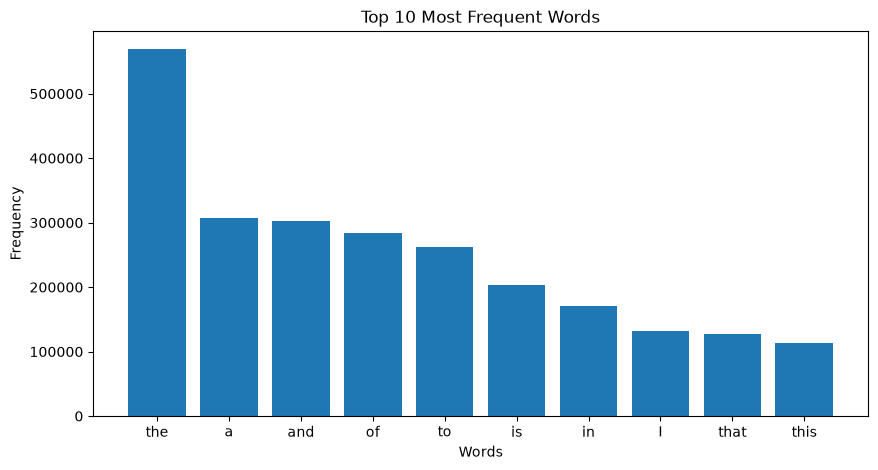

In [18]:
import matplotlib.pyplot as plt

words = [word for word, count in most_common]
frequencies = [count for word, count in most_common]

plt.figure(figsize=(10, 5))
plt.bar(words, frequencies)
plt.title("Top 10 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

In [19]:
html_examples = df[df["review"].str.contains(r"<[^>]+>", na=False)]

print("HTML Examples:")
for review in html_examples["review"].head(2):
    print(review[:500])
    print("-" * 50)

HTML Examples:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ
--------------------------------------------------
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, n

In [20]:
spacing_examples = df[df["review"].str.contains(r"\s{2,}", regex=True, na=False)]

print("Extra Spacing Examples:")
for review in spacing_examples["review"].head(2):
    print(review[:500])
    print("-" * 50)

Extra Spacing Examples:
Insignificant and low-brained (haha!) 80's horror like there are thirteen in a dozen, yet it can be considered amusing if you watch it in the right state of mind. The special effects are tacky, the acting atrocious and the screenplay seems to miss a couple of essential paragraphs! "The Brain" takes place in a typical quiet-American town setting, where every adolescent works in the same diner and where the cool-kid in high school flushes cherry bombs down the toilet. It is here that a TV-guru nam
--------------------------------------------------
The year 2005 saw no fewer than 3 filmed productions of H. G. Wells' great novel, "War of the Worlds". This is perhaps the least well-known and very probably the best of them. No other version of WotW has ever attempted not only to present the story very much as Wells wrote it, but also to create the atmosphere of the time in which it was supposed to take place: the last year of the 19th Century, 1900  using Wells' orig

In [23]:
import re

for review in df["review"]:
    if re.search(r" {2,}", review):
        print(repr(review[:500]))
        print("-" * 50)
        break

for review in df["review"]:
    if "" in review:
        print(repr(review[:500]))
        break

'Insignificant and low-brained (haha!) 80\'s horror like there are thirteen in a dozen, yet it can be considered amusing if you watch it in the right state of mind. The special effects are tacky, the acting atrocious and the screenplay seems to miss a couple of essential paragraphs! "The Brain" takes place in a typical quiet-American town setting, where every adolescent works in the same diner and where the cool-kid in high school flushes cherry bombs down the toilet. It is here that a TV-guru nam'


In [24]:
for review in df["review"]:
    if re.search(r"[A-Z]{4,}", review):
        print(review[:500])
        print("-" * 50)
        break

Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to make a film you must Decide if its a thriller or a drama! As a drama the movie is watchable. Parents are divorcing & arguing like in real life. And then we have Jake with his closet which totally ruins 
--------------------------------------------------


In [25]:
url_examples = df[df["review"].str.contains(
    r"https?://|www\.", case=False, na=False
)]

print("Number of reviews containing URLs:", len(url_examples))

for review in url_examples["review"].head(2):
    print(review[:500])
    print("-" * 50)

Number of reviews containing URLs: 202
Mario Lewis of the Competitive Enterprise Institute has written a definitive 120-page point-by-point, line-by-line refutation of this mendacious film, which should be titled A CONVENIENT LIE. The website address where his debunking report, which is titled "A SKEPTIC'S GUIDE TO AN INCONVENIENT TRUTH" can be found at is :www.cei.org. A shorter 10-page version can be found at: www.cei.org/pdf/5539.pdf Once you read those demolitions, you'll realize that alleged "global warming" is no more real or d
--------------------------------------------------
Following directly from where the story left off in part one, the second half which sets about telling the inevitable downfall and much more grim side of the man's legacy is exactly as such. In direct contrast to the first feature, part two represents a shift from Che the pride and glory of a revolutionised country, to Chestruggling liberator of a country to which he has no previous ties. The change of se

In [26]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt_tab')

sample_text = "I really enjoyed this movie! The acting was excellent, but the ending was disappointing."

tokens = word_tokenize(sample_text)

print(tokens)


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\aaari\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


['I', 'really', 'enjoyed', 'this', 'movie', '!', 'The', 'acting', 'was', 'excellent', ',', 'but', 'the', 'ending', 'was', 'disappointing', '.']


In [27]:
import re

tokens_regex = re.findall(r"\b\w+\b|[^\w\s]", sample_text)

print(tokens_regex)

['I', 'really', 'enjoyed', 'this', 'movie', '!', 'The', 'acting', 'was', 'excellent', ',', 'but', 'the', 'ending', 'was', 'disappointing', '.']


In [28]:
sample_text2 = "I didn't like this movie. It was a well-made, low-budget film!"

nltk_tokens = word_tokenize(sample_text2)
regex_tokens = re.findall(r"\b\w+\b|[^\w\s]", sample_text2)

print("NLTK Tokens:")
print(nltk_tokens)

print("\nRegex Tokens:")
print(regex_tokens)

NLTK Tokens:
['I', 'did', "n't", 'like', 'this', 'movie', '.', 'It', 'was', 'a', 'well-made', ',', 'low-budget', 'film', '!']

Regex Tokens:
['I', 'didn', "'", 't', 'like', 'this', 'movie', '.', 'It', 'was', 'a', 'well', '-', 'made', ',', 'low', '-', 'budget', 'film', '!']



Comparison of Two Tokenization Methods

We applied two tokenization methods: NLTK Word Tokenization and Regular Expression Tokenization.

Both methods produced similar results for a simple sentence. However, differences appeared when we tested contractions and hyphenated words.

NLTK divided "didn't" into "did" and "n't", while Regex divided it into "didn", an apostrophe, and "t".

NLTK kept "well-made" and "low-budget" together, while Regex separated them around the hyphens.

Conclusion: NLTK handles common English word structures more effectively than our basic regex pattern. Regex provides more control but requires a carefully designed pattern.


In [32]:
import re

sample_review = df["review"][0]

# 1. HTML Tags
html_tags = re.findall(r"<[^>]+>", sample_review)

# 2. URLs
urls = re.findall(r"https?://\S+|www\.\S+", sample_review)

# 3. Words containing apostrophes
contractions = re.findall(r"\b\w+['’]\w+\b", sample_review)

print("HTML Tags:", html_tags[:10])
print("URLs:", urls[:10])
print("Contractions:", contractions[:10])

HTML Tags: ['<br />', '<br />', '<br />', '<br />', '<br />', '<br />']
URLs: []
Contractions: ["you'll", "wouldn't", "doesn't", "couldn't", "who'll", "who'll"]


In [ ]:
''' 
### Regex Patterns Used

We applied three regular expression patterns to the IMDb movie reviews dataset.

1. **HTML Tag Detection (`<[^>]+>`):** Detects HTML tags such as `<br />` that appear in reviews.
2. **URL Detection (`https?://\S+|www\.\S+`):** Detects website addresses and links in reviews.
3. **Contraction Detection (`\b\w+['’]\w+\b`):** Detects words containing apostrophes, such as "you'll", "wouldn't", and "doesn't".

These patterns help identify different text structures and potential challenges in movie review processing.
'''

In [ ]:
'''
### Tokenization Challenges

During tokenization of IMDb movie reviews, we identified the following challenges:

**1. Contractions:** Words such as "didn't", "wouldn't", and "you'll" can be split differently by different tokenizers. For example, NLTK splits "didn't" into "did" and "n't", whereas our basic regex tokenizer splits it into "didn", an apostrophe, and "t".

**2. Hyphenated Words:** Words such as "well-made" and "low-budget" can also be handled differently. NLTK keeps these words together, whereas our regex tokenizer separates them around the hyphen.

These differences show that choosing an appropriate tokenizer is important for accurate text processing and sentiment analysis.
'''